# Project Python Foundations: FoodHub Data Analysis

**Marks: 60**

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

In [ ]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [ ]:
# uncomment and run the following lines for Google Colab
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# read the data
df = pd.read_csv('/content/drive/MyDrive/Python/foodhub_order.csv')
# returns the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


In [ ]:
df.tail()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
1893,1476701,292602,Chipotle Mexican Grill $1.99 Delivery,Mexican,22.31,Weekend,5,31,17
1894,1477421,397537,The Smile,American,12.18,Weekend,5,31,19
1895,1477819,35309,Blue Ribbon Sushi,Japanese,25.22,Weekday,Not given,31,24
1896,1477513,64151,Jack's Wife Freda,Mediterranean,12.18,Weekday,5,23,31
1897,1478056,120353,Blue Ribbon Sushi,Japanese,19.45,Weekend,Not given,28,24


#### **Observations:**

The DataFrame has 9 columns as mentioned in the Data Dictionary. Data in each row corresponds to the order placed by a customer.

### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [ ]:
# Write your code here
df.shape

(1898, 9)





#### **Observations:**
The dataset has **1898** rows and **9** columns.


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [ ]:
# Use info() to print a concise summary of the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### **Observations:**

*   The dataframe has total of 9 columns and below are the data types,

    *   **4 object datatypes** (object64)
    *   **4 numerical datatypes** (int64)
    *   **1 float datatype** (float64)




In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,1898.0,1.477496e+06,548.049724,1476547.00,1477021.25,1477495.50,1.477970e+06,1478444.00
customer_id,1898.0,1.711685e+05,113698.139743,1311.00,77787.75,128600.00,2.705250e+05,405334.00
cost_of_the_order,1898.0,1.649885e+01,7.483812,4.47,12.08,14.14,2.229750e+01,35.41
food_preparation_time,1898.0,2.737197e+01,4.632481,20.00,23.00,27.00,3.100000e+01,35.00
delivery_time,1898.0,2.416175e+01,4.972637,15.00,20.00,25.00,2.800000e+01,33.00


In [ ]:
df.describe(include= 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,1898.0,NaN,NaN,NaN,1477495.5,548.049724,1476547.0,1477021.25,1477495.5,1477969.75,1478444.0
customer_id,1898.0,NaN,NaN,NaN,171168.478398,113698.139743,1311.0,77787.75,128600.0,270525.0,405334.0
restaurant_name,1898,178,Shake Shack,219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine_type,1898,14,American,584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_the_order,1898.0,NaN,NaN,NaN,16.498851,7.483812,4.47,12.08,14.14,22.2975,35.41
day_of_the_week,1898,2,Weekend,1351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1898,4,Not given,736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
food_preparation_time,1898.0,NaN,NaN,NaN,27.37197,4.632481,20.0,23.0,27.0,31.0,35.0
delivery_time,1898.0,NaN,NaN,NaN,24.161749,4.972637,15.0,20.0,25.0,28.0,33.0


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [ ]:
# Write your code here
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


####**Observations:**

All the 9 columns have 1898 observations, which means none of the columns has null values. There are no missing values in the dataset.


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [ ]:
# Write your code here
df['food_preparation_time'].describe()

,food_preparation_time
count,1898.000000
mean,27.371970
std,4.632481
min,20.000000
25%,23.000000
50%,27.000000
75%,31.000000
max,35.000000


In [ ]:
#specific values
print("minimum:",df['food_preparation_time'].min())
print("maximum:",df['food_preparation_time'].max())
print("average:",df['food_preparation_time'].mean())

minimum: 20
maximum: 35
average: 27.371970495258168


#### Observations:

There are no missing values in the 'food_preparation_time' column in the dataset.

Here is the statistical summary:

*   Minimum time for food preparation is **20 minutes**
*   Average time for food preparation is **27.3719 minutes**
*   Maximum time for food preparation is **35 minutes**











### **Question 5:** How many orders are not rated? [1 mark]

In [ ]:
# Write the code here
len(df[df['rating'] == 'Not given'])

736

In [ ]:
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


#### **Observations:**

A total of **736** orders out of 1898 have not been rated by customers, about **38%** of the orders does not have any ratings.


*  rating marked as 'Not given'


### **Exploratory Data Analysis (EDA)**

### **Univariate Analysis**

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

### **Order ID**

In [ ]:
#Check unique order ID
df['order_id'].nunique()

1898

### **Observation**


*  As mentioned in the data dictionary,**'order_id'** is an unique identifier for the orders.

* There are about **1898** unique orders.




### **Customer** **ID**

In [ ]:
#check unique customer ID
df['customer_id'].nunique()

1200

### **Observation**


*   There are **1200** unique customers in the dataset, about **63%** of the users are new customers and only **27%** of the dataset are repeat customers.



### **Restaurant Name**

In [ ]:
#check unique restaurant name
df['restaurant_name'].nunique()

178

In [ ]:
df['restaurant_name'].value_counts()

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68
...,...
Rye House,1
Hiroko's Place,1
Frank Restaurant,1


### **Observation**


*   There are **178** unique restaurants in the dataset.
* The top 3 restaurants with the most orders,

    *   Shake Shack (219)
    *   The Meatball Shop (132)
    *   Blue Ribbon Sushi (119)



### **Observations on cuisine type**

In [ ]:
#check unique cuisine type
df['cuisine_type'].nunique()

14

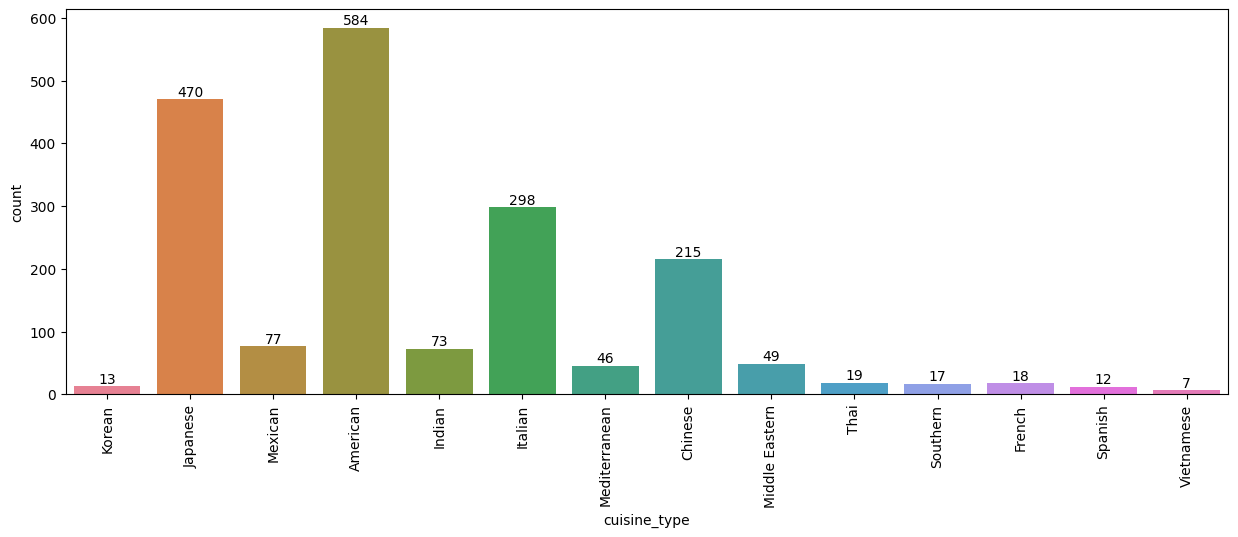

In [ ]:
plt.figure(figsize=(15,5))
ax = sns.countplot(data=df, x='cuisine_type', hue='cuisine_type')
plt.xticks(rotation=90)

for container in ax.containers:
    ax.bar_label(container)
plt.show()

#### **Observations:**

* There are **14** different cuisine types available on the platform.

* American cuisine is the most popular, with the highest number of orders (584), which is 31% of the total orders, followed by 25% from Japanese (470), and 16% from Italian (298).


* The least preferred cuisines are Vietnamese (7), Spanish (12) and Korean (13).


### **Observations on cost of the order**

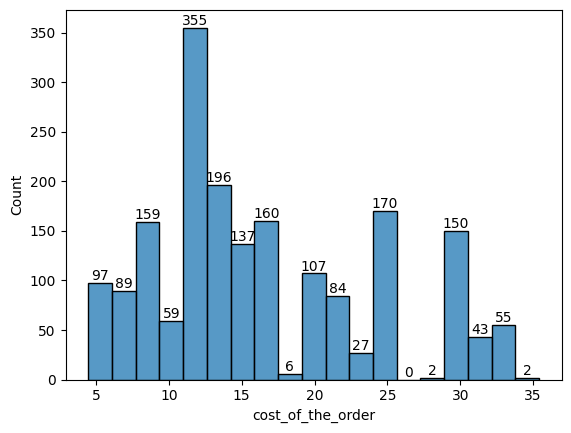

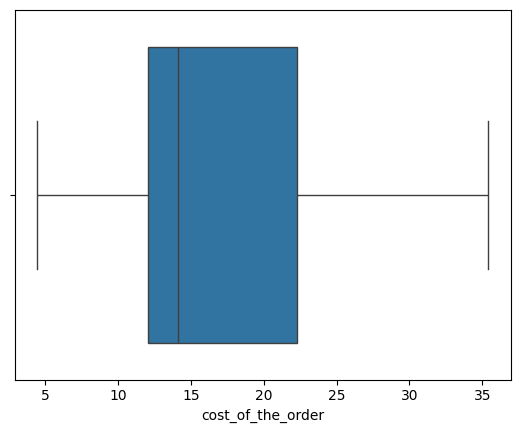

In [ ]:
# Write the code here
ax= sns.histplot(data=df, x= 'cost_of_the_order')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

sns.boxplot(data=df, x='cost_of_the_order')
plt.show()

In [ ]:
df['cost_of_the_order'].describe()

,cost_of_the_order
count,1898.000000
mean,16.498851
std,7.483812
min,4.470000
25%,12.080000
50%,14.140000
75%,22.297500
max,35.410000


In [ ]:
print("Median:",df['cost_of_the_order'].median())

Median: 14.14


#### **Observations:**

*  The average cost of the order is $16.50 dollars.

* The median cost is $14.14 dollars, which is lower than the mean, confirming the distribution is right skewed.

*  Most of the orders are concentrated in the lower price range (between 4 and 20 dollars)

*   There are no outliers present in the dataset.







### **Observations on day of the week**

In [ ]:
df['day_of_the_week'].value_counts(normalize= True)

,proportion
day_of_the_week,
Weekend,0.711802
Weekday,0.288198


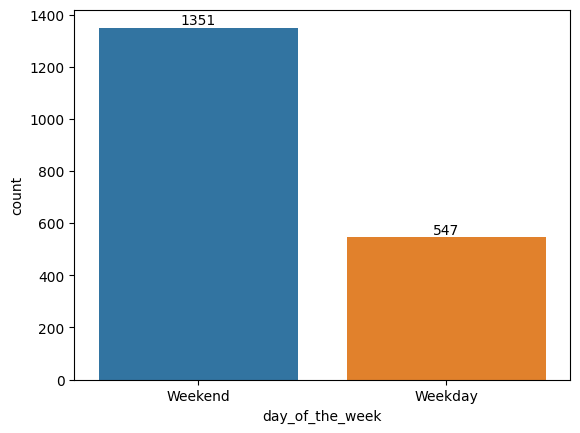

In [ ]:
ax=sns.countplot(data=df, x='day_of_the_week', hue='day_of_the_week')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

#### **Observations:**

*   The number of orders on weekends is significantly higher than on weekdays.
    * **71%** of the orders were placed and delivered on weekends
    * **28%** of the orders were placed and delivered on weekdays

*   This indicates that customers prefer ordering food on weekends

### **Observations on rating**

In [ ]:
#check the unique values
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


In [ ]:
df['rating'].value_counts(normalize=True)

,proportion
rating,
Not given,0.387777
5,0.309800
4,0.203372
3,0.099052


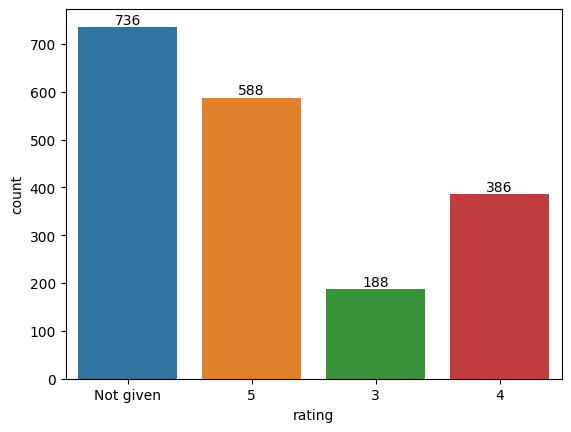

In [ ]:
ax= sns.countplot(data=df, x='rating', hue= 'rating')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

#### **Observations:**

*   The most frequent value is "Not given", almost **39%** of the custmores are not rating their orders.

*   Among the ratings,
    * **31%** of the customers have given a rating of 5
    * **20%** of the customers have given a rating of 4
    * **10%** of the customers have given a rating of 3

### **Observations on food preparation time**

In [ ]:
df['food_preparation_time'].describe()

,food_preparation_time
count,1898.000000
mean,27.371970
std,4.632481
min,20.000000
25%,23.000000
50%,27.000000
75%,31.000000
max,35.000000


In [ ]:
print("Median:", df['food_preparation_time'].median())

Median: 27.0


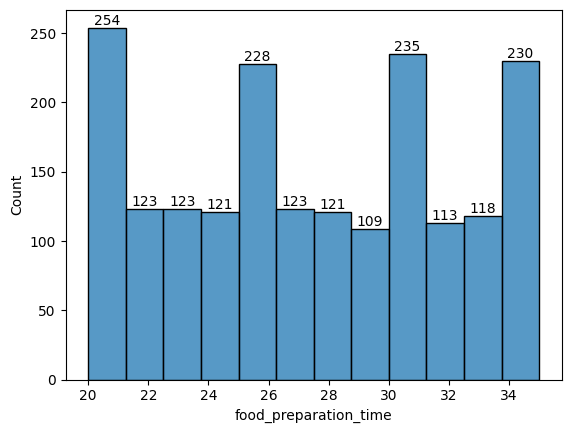

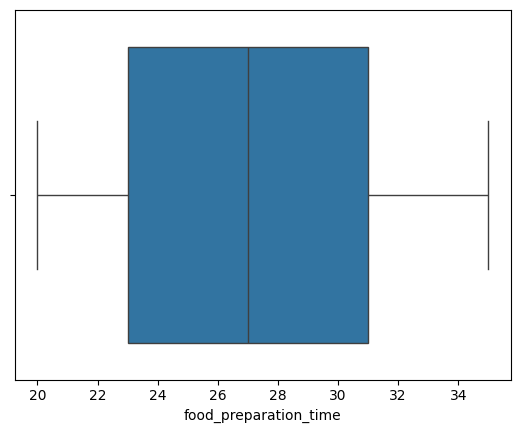

In [ ]:
ax=sns.histplot(data=df, x='food_preparation_time')

for container in ax.containers:
    ax.bar_label(container)

plt.show()
plt.show()


sns.boxplot(data=df, x='food_preparation_time')
plt.show()

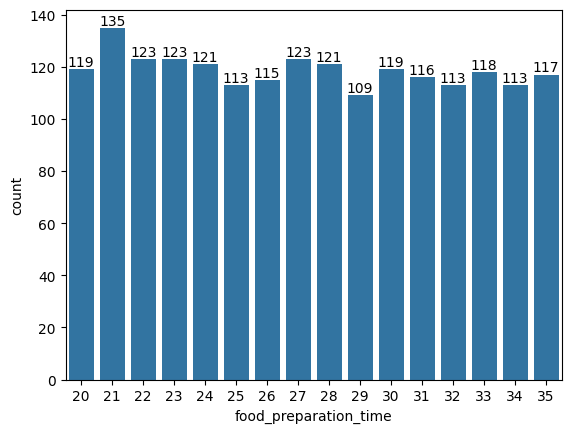

In [ ]:
ax= sns.countplot(data=df, x='food_preparation_time')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

#### **Observations:**

*   The distribution of food preparation time is roughly uniform  
*   The preparation time ranges between 20 to 35 minutes with an average of 27 minutes


*   There are no significant outliers in this variable, indicating consistent preparation time across restaurants






### **Observations on delivery time**

In [ ]:
df['delivery_time'].describe()

,delivery_time
count,1898.000000
mean,24.161749
std,4.972637
min,15.000000
25%,20.000000
50%,25.000000
75%,28.000000
max,33.000000


In [ ]:
print("Median: ",df['delivery_time'].median())

Median:  25.0


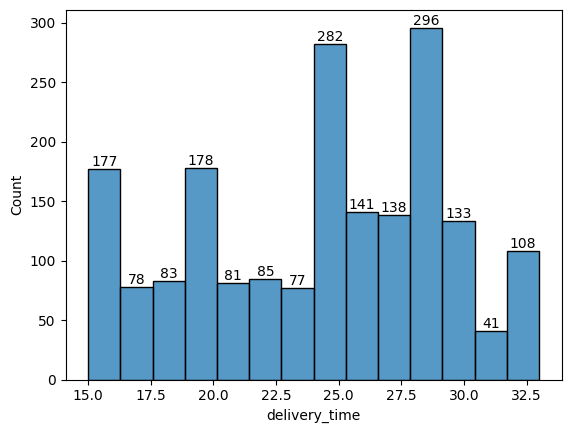

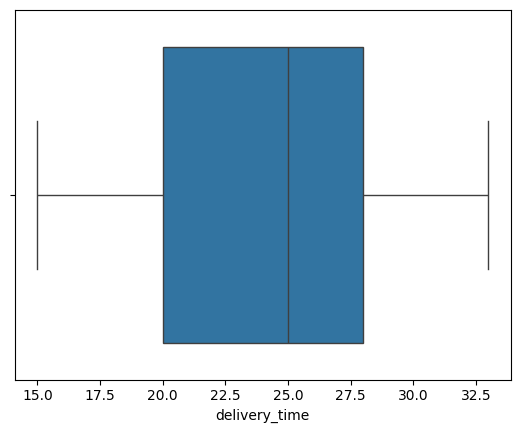

In [ ]:
ax= sns.histplot(data=df, x='delivery_time')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

sns.boxplot(data=df, x='delivery_time')
plt.show()



#### **Observations:**

* The average delivery time of the orders is 24 minutes.

* The median delivery time of the orders is 25 minutes.
* The distribution of delivery time is slightly left skewed.


*   Most deliveries are completed between 20 to 28 minutes.

*   There are no significant outliers, indicating delivery time is fairly consistent.






### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [ ]:
# Write the code here
df['restaurant_name'].value_counts().head(5)

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### **Observations:**

*   The top 5 restaurants with the most orders,

      * Shake Shack (219)
      * The Meatball Shop (132)
      * Blue Ribbion Sushi (119)
      * Parm (68)

* Shake Shack leads the platform in order volume, making it the most popular restaurant among customers.

*   The top 5 restaurants collectively drive a significant share of the platform's total orders. (33% of the total orders)

*   Order volume declines notably from the 1st to the 5th ranked restaurant, indicating a concentration of demand at the top.












### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [ ]:
# Write the code here
Weekend_df = df[df['day_of_the_week']== 'Weekend']
popular_cuisine = Weekend_df['cuisine_type'].value_counts()
popular_cuisine.head(1)

,count
cuisine_type,
American,415


In [ ]:
df[df['day_of_the_week'] == 'Weekend']['cuisine_type'].value_counts().head(1)

,count
cuisine_type,
American,415


#### **Observations:**


*   American cuisine is the most popular cuisine ordered on weekends.
*   The demand for American cuisine on weekends is significantly higher compared to other cuisine types



### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [ ]:
# Write the code here
orders_above_20 = df[df['cost_of_the_order'] > 20]
percentage_above_20 = (len(orders_above_20)/len(df))*100
print(percentage_above_20)

29.24130663856691



#### **Observations:**
*  Around **29.24%** of the total orders have the cost of the order greater than $20

*  This indicates that the majority of customers tend to place orders below $20 dollars


*  This is consistent with the right-skewed distribution observed in the univariate analysis of the **'cost_of_the_order'** variable






### **Question 10**: What is the mean order delivery time? [1 mark]

In [ ]:
# Write the code here
mean_delivery_time= round(df['delivery_time'].mean(),2)
print(mean_delivery_time)

24.16


#### **Observations:**


*  The mean delivery time for orders is around **24.16 minutes**

*  This gives us an idea of the average time a customer has to wait for their order to be delivered.







### **Question 11:** The company has decided to give 20% discount vouchers to the top 5 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [ ]:
# Write the code here
top_5_customers= df['customer_id'].value_counts().head(5)
print(top_5_customers)

customer_id
52832     13
47440     10
83287      9
250494     8
259341     7
Name: count, dtype: int64


In [ ]:
df.groupby('customer_id')['order_id'].count().sort_values(ascending= False).head(5)

,order_id
customer_id,
52832,13
47440,10
83287,9
250494,8
276192,7


#### **Observations:**

*   The top 5 most frequent customers (customer id) with the most number of orders placed,

    * 52832
    * 47440
    * 83287
    * 250494
    * 276192


*   These customers are the most active on the platform and are eligible for the 20% discount voucher




### **Multivariate Analysis**

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


### **Let us plot charts between variables to understand their interaction with each other**

### **Relationship between Cost of the Order and Day of the Week**

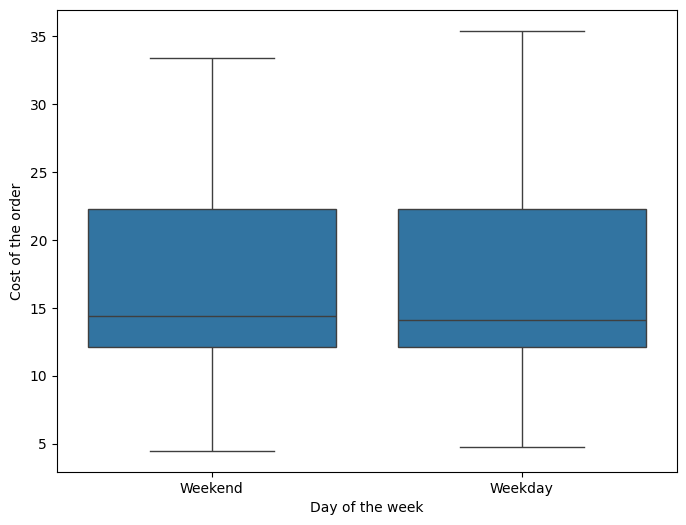

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='day_of_the_week', y='cost_of_the_order')
plt.xlabel('Day of the week')
plt.ylabel('Cost of the order')
plt.show()

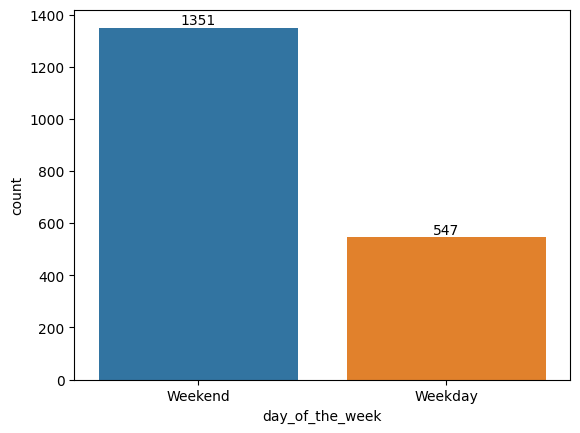

In [ ]:
ax=sns.countplot(data=df, x= 'day_of_the_week', hue='day_of_the_week')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

#### **Observations:**


* **71%** of the total orders were placed on weekends and **29%** in weekdays.

*   The median cost of orders is slightly higher on weekends compared to weekdays.

*   The spread of cost is wider on weekdays compared to weekends, indicating more variation in order costs on weekdays.

*   There are no outliers present in either category.



### **Relationship between Delivery Time and Day of the Week**





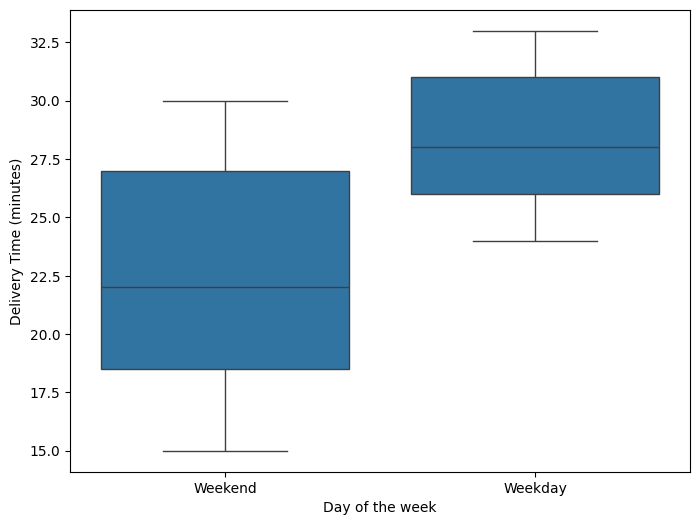

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='day_of_the_week', y='delivery_time')
plt.xlabel('Day of the week')
plt.ylabel('Delivery Time (minutes)')
plt.show()

#### **Observations:**

*   The spread of delivery time is wider on weekdays, indicating more variation in delivery times during weekdays.
*  The delivery times in weekdays are higher than weekends.

*   The median delivery time on weekdays is higher compared to weekends.

*   There are no outliers present in either category.





### **Relationship between Cost of Order and Cuisine Type**

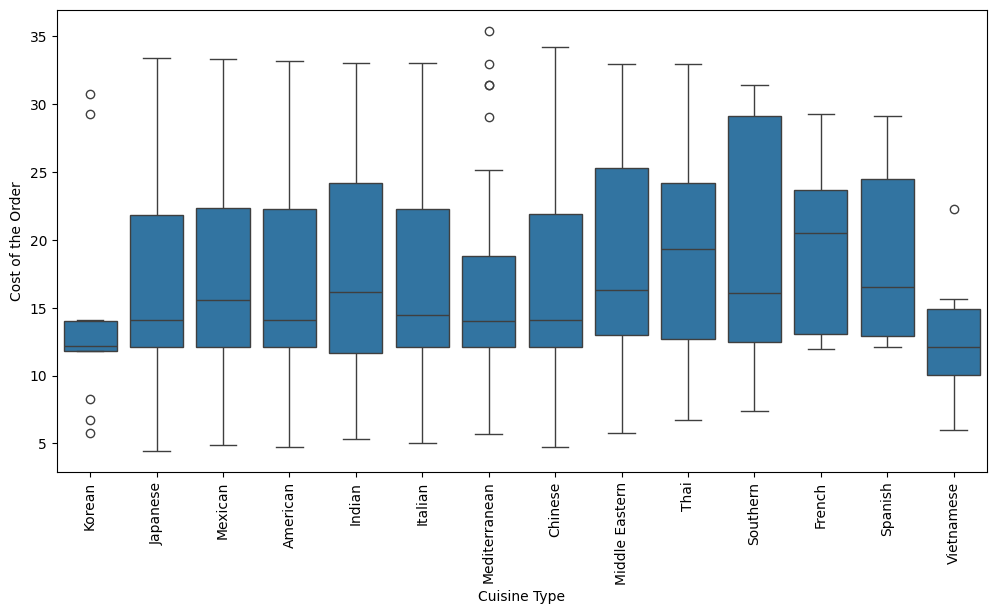

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='cuisine_type', y='cost_of_the_order')
plt.xticks(rotation=90)
plt.xlabel('Cuisine Type')
plt.ylabel('Cost of the Order')
plt.show()

#### **Observations:**

*   There are noticeable difference in the cost of orders across different cuisine types.
*   Thai and French cuisines have the highest median cost
compared to all other cuisine types.  
*   Korean and Vietnamese cuisines have the lowest median
cost compared to all other cuisine types.
*   Mediterranean cuisine has outliers on the higher end,
indicating some very expensive orders exist.
*   Korean cuisine has outliers on the lower end,
indicating some very cheap orders exist.
*   American cuisine, despite being the most popular,
has a relatively lower median cost.








### **Correlation by Heatmap**

In [ ]:
#numerical columns of the variable
num_col= df[['cost_of_the_order', 'food_preparation_time', 'delivery_time']]
#correlation
corr= num_col.corr()

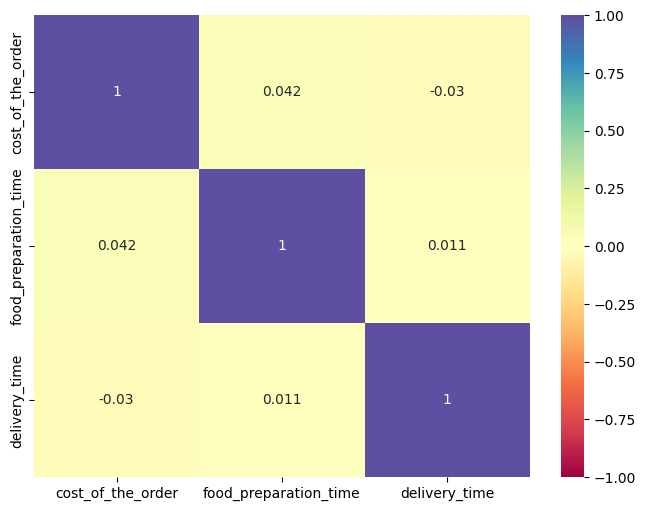

In [ ]:
#heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, vmax=1, vmin=-1, cmap='Spectral')
plt.show()

#### **Observations:**


*  There is no strong correlation between any of the numerical variables
*  Food preparation time and delivery time have a very weak correlation, indicating they are largely independent of each other.
*  It is important to note that correlation does not imply causation

Since we have seen that day of the week has an effect on the cost of orders, let's check if that effect is present across different cuisine types.

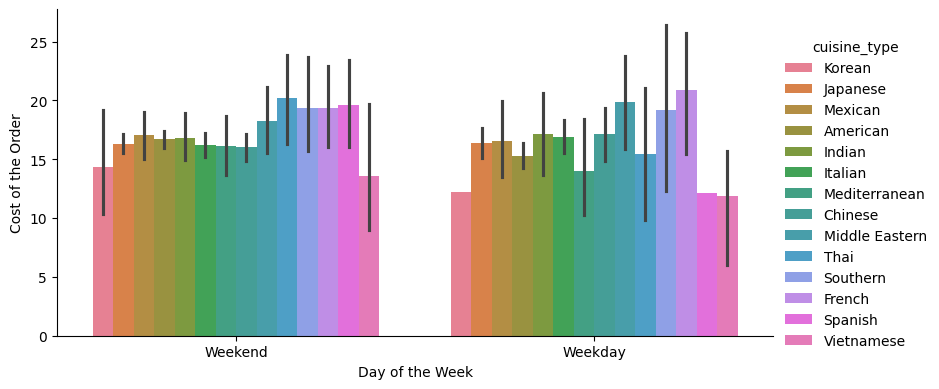

In [ ]:
sns.catplot(x='day_of_the_week', y='cost_of_the_order', data=df, kind='bar' , hue='cuisine_type', height=4, aspect=2)
plt.xlabel('Day of the Week')
plt.ylabel('Cost of the Order')
plt.show()

#### **Observations:**


*   The average cost of orders is fairly similar across
  most cuisine types on both weekdays and weekends.
*   Thai and Spanish cuisines have the highest average
  cost on weekends, while French cuisine has the highest average cost on weekdays.
*   Korean and Vietnamese cuisines consistently show
  the lowest average cost on both weekdays and weekends.
* Thai and Spanish cuisines have most of the orders on weekends and they seem to drop during the weekdays.
*   The cost pattern across cuisine types does not change
  significantly between weekdays and weekends, indicating that day of the week does not strongly affect the cost of orders for most cuisines.





### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [ ]:
# Write the code here
df_rated = df[df['rating'] != 'Not given'].copy()
df_rated['rating'] = df_rated['rating'].astype(int)

In [ ]:
# grouping by restaurant name
restaurant_ratings = df_rated.groupby('restaurant_name')['rating'].agg(['count', 'mean'])


In [ ]:
# applying the conditions: count > 50 and mean > 4
promo_restaurants = restaurant_ratings[(restaurant_ratings['count'] > 50) &
                                        (restaurant_ratings['mean'] > 4)]
print(promo_restaurants)

                           count      mean
restaurant_name                           
Blue Ribbon Fried Chicken     64  4.328125
Blue Ribbon Sushi             73  4.219178
Shake Shack                  133  4.278195
The Meatball Shop             84  4.511905


#### **Observations:**

*   These **4** restaurants that are eligible for the promotional offer by fulfiling the criteria of having a rating
count of more than 50 and an average rating greater than 4.
*   Shake Shack has received the highest number of ratings **133** among the qualifying restaurants.
*   The Meatball Shop has the highest average rating **4.51** among the qualifying restaurants.
*   These restaurants have consistently received positive feedback from customers and are eligible for the promotional offer.





### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [ ]:
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


In [ ]:
# Write the code here
#company charges the restaurant 25% on orders costing more than 20 dollars
revenue_above_20 = df[df['cost_of_the_order'] > 20]['cost_of_the_order'].sum() * 0.25
print(revenue_above_20)


3688.7275


In [ ]:
# company charges the restaurant 15% on orders costing greater than 5 dollars but less than or equal to 20 dollars
revenue_5_to_20 = df[(df['cost_of_the_order'] > 5) &
                      (df['cost_of_the_order'] <= 20)]['cost_of_the_order'].sum() * 0.15
print(revenue_5_to_20)

2477.5755000000004


In [ ]:
# total net revenue
net_revenue = revenue_above_20 + revenue_5_to_20
print(net_revenue)

6166.303


In [ ]:
# Creating a funtion to calculate Revenue

def calculate_revenue(x):
  if x > 20:
    return x * 0.25
  elif 5 < x <= 20:
    return x * 0.15
  else:
    return 0

In [ ]:
df['revenue'] = df['cost_of_the_order'].apply(calculate_revenue)
print(df['revenue'].sum())

6166.303


#### **Observations:**


*   The net revenue generated by the company across all orders is **$ 6166.303**
*   The majority of the revenue comes from orders costing more than 20 dollars as the commission rate is higher 25% for those orders







### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [ ]:
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time,revenue
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20,7.6875
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23,1.8120
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28,1.8345
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15,7.3000
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24,1.7385


In [ ]:
# Write the code here
df['total_time'] = df['food_preparation_time'] + df['delivery_time']


In [ ]:
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time,revenue,total_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20,7.6875,45
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23,1.8120,48
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28,1.8345,51
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15,7.3000,40
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24,1.7385,49


In [ ]:
orders_above_60 = df[df['total_time'] > 60]
percentage_above_60 = (len(orders_above_60) / len(df)) * 100
print(percentage_above_60)

10.537407797681771


#### **Observations:**


*   **10.53%** of orders take more than 60 minutes to get delivered from the time the order is placed.
*   This indicates that majority of the orders are prepared and delivered under an hour, and only 10.53% of orders takes 1 hour or more. This could also affect customer satisfaction.





### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [ ]:
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time,revenue,total_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20,7.6875,45
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23,1.8120,48
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28,1.8345,51
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15,7.3000,40
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24,1.7385,49


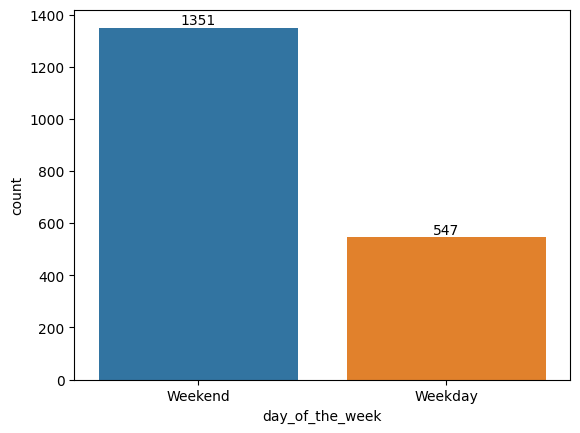

In [ ]:
ax=sns.countplot(data=df, x= 'day_of_the_week', hue='day_of_the_week')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

In [ ]:
df['day_of_the_week'].value_counts(normalize= True)

,proportion
day_of_the_week,
Weekend,0.711802
Weekday,0.288198


In [ ]:
mean_food_preparation_time = df.groupby('day_of_the_week')['food_preparation_time'].mean()
print(mean_food_preparation_time)

day_of_the_week
Weekday    27.212066
Weekend    27.436714
Name: food_preparation_time, dtype: float64


In [ ]:
# Write the code here
mean_delivery = df.groupby('day_of_the_week')['delivery_time'].mean()
print(mean_delivery)

day_of_the_week
Weekday    28.340037
Weekend    22.470022
Name: delivery_time, dtype: float64


#### **Observations:**


*   The mean delivery time on weekdays **28.34 mins** higher compared to weekends **22.47 mins**
*   Looking at the total orders received, 71% of the orders were on weekends, and only 29% were in weekdays. There are no significant difference in the average food preparation time compared to the day of the week.

* This suggests that weekday deliveries take longer, and company should look into optimizing delivery operations on weekdays to improve customer experience.





### **Conclusion and Recommendations**

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### **Conclusions:**

*   The dataset consists of **1898** orders across **178**
    restaurants with **9 columns** and no missing values,
    making it clean and ready for analysis

*   **American cuisine** is the most popular cuisine on
    the platform with 31% of total orders, followed
    by **Japanese** (25%) and **Italian** (16%). The least
    preferred cuisines are **Vietnamese, Spanish and Korean**.

*   **71%** of the total orders were placed on weekends
    and only **29%** on weekdays, indicating that customers
    strongly prefer ordering food on weekends.

*   **Shake Shack** is the most popular restaurant with
    **219** orders, and the top 5 restaurants collectively
    drive **33%** of the total orders on the platform.

*   **The majority of customers prefer lower priced
    orders** as most orders are concentrated between
    $4 and $20, with only 29.24% of orders costing
    more than $20.

*   The mean food preparation time is **27.37 minutes**
    and the mean delivery time is **24.16 minutes**,
    giving a total average time of around **51 minutes**
    per order.

*   **10.53%** of orders take more than 60 minutes from
    placement to delivery, which could negatively
    affect customer satisfaction.

*   **39%** of customers have not rated their orders,
    indicating low feedback engagement on the platform.
    Among rated orders, **31%** gave a rating of 5 and
    **20%** gave a rating of 4.

*   Only 4 restaurants qualify for the promotional
    offer - Shake Shack, The Meatball Shop, Blue
    Ribbon Fried Chicken and Blue Ribbon Sushi, as
    they have consistently high ratings and sufficient
    rating count.

*   The net revenue generated by the company across
    all orders is **$6166.30**, with the majority coming
    from orders costing more than $20.

*   Weekday deliveries take significantly longer
    (28.34 mins) compared to weekends (22.47 mins),
    indicating inefficiency in weekday delivery
    operations.

*   There is no strong correlation between cost,
    food preparation time and delivery time, indicating
    these variables are largely independent of each other

### **Recommendations:**

*   **American cuisine** is the most popular cuisine with
    **31%** of total orders, especially on weekends. The
    company should partner with more American cuisine
    restaurants to meet the high demand on weekends.

*   **71%** of orders are placed on weekends, the company
    should ensure sufficient delivery staff and
    restaurant availability on weekends to handle
    the high demand efficiently.

*   The mean delivery time on weekdays (28.34 mins)
    is significantly higher than weekends (22.47 mins).
    The company should look into **optimizing delivery
    operations on weekdays** to improve customer experience.

*   **10.53%** of orders take more than 60 minutes from
    placement to delivery. The company should set a
    maximum delivery time limit and notify customers
    about delays to improve their experience.

*   **39%** of customers are not rating their orders.
    The company should **encourage customers to rate
    their orders by offering incentives** like discount
    coupons to improve feedback engagement.

*   Only 4 restaurants - Shake Shack, The Meatball
    Shop, Blue Ribbon Fried Chicken and Blue Ribbon
    Sushi - qualify for the promotional offer. The
    company should promote these restaurants as they
    have consistently high ratings and positive
    customer feedback.

*   Thai and French cuisines have the highest median
    cost. The company can focus on **premium marketing
    strategies** for these cuisines to attract higher
    spending customers.

*   Vietnamese, Spanish and Korean cuisines have the
    least number of orders. The company should
    **investigate the low demand** for these cuisines
    and explore ways to increase their popularity
    on the platform.

*   **Only 27% of customers are repeat customers**. The
    company should introduce loyalty programs and
    offers to convert new customers into repeat
    customers and improve customer retention

---